# First Linear Regression Predictor for Adsorption Capacity

**Input workbook:** `ExpData(1).xlsx` (the compiled dataset supplied with this notebook)  
**Target:** `qe_mgg` — adsorption capacity in mg/g  
**Purpose:** a transparent, reproducible *first baseline*, not a publication-ready or externally validated model.

## What this notebook does
1. Loads and audits the workbook without modifying the original file.
2. Converts the two reported pH intervals to their midpoints, flags those approximations, and reports how many were converted.
3. Removes exact duplicate rows from modelling (while recording the count).
4. Excludes `Ce_mgL` from predictors because equilibrium concentration is measured after adsorption and is algebraically linked to the target by the mass-balance equation.
5. Leaves the very sparse elemental-composition columns out of the *primary* model; they are reported in the audit for a later sensitivity analysis.
6. Imputes missing predictor values inside a scikit-learn pipeline, so imputation is fitted on training folds only.
7. Fits `LinearRegression`, compares against a training-median baseline, calculates cross-validation and hold-out metrics, plots diagnostics, and saves the model and outputs.

> **Important limitations in the source workbook:** pollutant identity, adsorbent/sample identity and paper/DOI are not columns in this file. A random row split is therefore only a preliminary benchmark: related experimental points from the same material/source may appear in both training and test data. Do not describe the resulting score as reliable performance on unseen pollutants or unseen materials. Add source/group identifiers and use grouped validation before making that claim.

## 1. Imports and configuration

The defaults are chosen to run directly on the supplied workbook. You generally do not need to change the feature list for the first run. The notebook will look for `ExpData(1).xlsx` beside the notebook/current working directory, and then in `/mnt/data`. Keep the Excel file and notebook together when moving them to another computer.

In [1]:
from pathlib import Path
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_SPLITS = 5
REMOVE_EXACT_DUPLICATES = True
CONVERT_PH_RANGES_TO_MIDPOINT = True

TARGET = "qe_mgg"
# Deliberately exclude Ce_mgL (target leakage risk) and high-missingness composition fields.
FEATURES = [
    "BET_m2g",
    "pore_vol_cm3g",
    "pH_pzc",
    "C0_mgL",
    "pH",
    "dose_gL",
    "contact_time_min",
    "temp_K",
]
COMPOSITION_COLUMNS = ["C_pct", "H_pct", "O_pct", "N_pct"]
LEAKAGE_RISK_COLUMNS = ["Ce_mgL"]

print("Python imports loaded.")
print("Primary features:", FEATURES)
print("Target:", TARGET)

Python imports loaded.
Primary features: ['BET_m2g', 'pore_vol_cm3g', 'pH_pzc', 'C0_mgL', 'pH', 'dose_gL', 'contact_time_min', 'temp_K']
Target: qe_mgg


In [2]:
def locate_workbook():
    """Find the supplied workbook, preferring its exact uploaded filename."""
    preferred = [
        Path("ExpData(1).xlsx"),
        Path.cwd() / "ExpData(1).xlsx",
        Path("/mnt/data/ExpData(1).xlsx"),
        Path("ExpData.xlsx"),
        Path.cwd() / "ExpData.xlsx",
        Path("/mnt/data/ExpData.xlsx"),
    ]
    for candidate in preferred:
        if candidate.is_file():
            return candidate.resolve()

    search_dirs = [Path.cwd(), Path("/mnt/data")]
    matches = []
    for folder in search_dirs:
        if folder.is_dir():
            matches.extend(folder.glob("ExpData*.xlsx"))
    matches = list(dict.fromkeys(p.resolve() for p in matches if p.is_file()))
    if len(matches) == 1:
        return matches[0]
    if len(matches) > 1:
        names = "\n".join(f" - {p}" for p in matches)
        raise FileNotFoundError(
            "Found multiple ExpData*.xlsx files. Keep the correct workbook named "
            "'ExpData(1).xlsx' beside the notebook, or edit the path explicitly:\n" + names
        )
    raise FileNotFoundError(
        "Could not find ExpData(1).xlsx. Place it beside this notebook or edit DATA_PATH manually."
    )

DATA_PATH = locate_workbook()
OUTPUT_DIR = DATA_PATH.parent
print(f"Workbook: {DATA_PATH}")
print(f"Output folder: {OUTPUT_DIR}")

Workbook: D:\Downloads\Project\ExpData.xlsx
Output folder: D:\Downloads\Project


In [3]:
# Load the first worksheet. The source workbook is read only; it is not edited.
raw_df = pd.read_excel(DATA_PATH, sheet_name=0)
raw_df.columns = [str(c).strip() for c in raw_df.columns]

required_columns = set(FEATURES + COMPOSITION_COLUMNS + LEAKAGE_RISK_COLUMNS + [TARGET])
missing_columns = sorted(required_columns - set(raw_df.columns))
if missing_columns:
    raise ValueError(
        "The workbook is missing expected columns: " + ", ".join(missing_columns)
        + "\nPlease check the header row and update the column names in this notebook if needed."
    )

# Excel row numbers are retained to make suspicious records traceable to the source sheet.
raw_df.insert(0, "_excel_row", np.arange(2, len(raw_df) + 2))
print(f"Raw workbook shape: {len(raw_df):,} rows × {len(raw_df.columns)-1:,} data columns")
display(raw_df.head(10))

Raw workbook shape: 488 rows × 14 data columns


,_excel_row,BET_m2g,pore_vol_cm3g,pH_pzc,C_pct,H_pct,O_pct,N_pct,C0_mgL,pH,dose_gL,contact_time_min,temp_K,Ce_mgL,qe_mgg
0,2,685.0,0.30,NaN,NaN,NaN,NaN,NaN,67.1,6.2,1.0,1440.0,298.15,23.9,43.2
1,3,685.0,0.30,NaN,NaN,NaN,NaN,NaN,101.5,6.2,1.0,1440.0,298.15,42.7,58.8
2,4,685.0,0.30,NaN,NaN,NaN,NaN,NaN,128.4,6.2,1.0,1440.0,298.15,66.0,62.4
3,5,685.0,0.30,NaN,NaN,NaN,NaN,NaN,141.8,6.2,1.0,1440.0,298.15,74.5,67.3
4,6,685.0,0.30,NaN,NaN,NaN,NaN,NaN,224.0,6.2,1.0,1440.0,298.15,156.7,67.3
5,7,685.0,0.30,NaN,NaN,NaN,NaN,NaN,335.1,6.2,1.0,1440.0,298.15,258.6,76.5
6,8,685.0,0.30,NaN,NaN,NaN,NaN,NaN,430.8,6.2,1.0,1440.0,298.15,339.1,91.7
7,9,831.0,0.38,NaN,NaN,NaN,NaN,NaN,67.0,6.2,1.0,1440.0,298.15,23.8,43.2
8,10,831.0,0.38,NaN,NaN,NaN,NaN,NaN,101.4,6.2,1.0,1440.0,298.15,23.8,77.6
9,11,831.0,0.38,NaN,NaN,NaN,NaN,NaN,128.3,6.2,1.0,1440.0,298.15,29.8,98.5


## 2. Data-quality audit

Missing measurements are not automatically errors: some material descriptors were not reported for many experiments. However, high missingness limits what can be learned from those columns. The audit below reports missing counts, numeric ranges, duplicate rows, and unexpected text values. It does **not** delete unusual target values merely because they are large.

In [4]:
data_columns = [c for c in raw_df.columns if c != "_excel_row"]
missing_summary = pd.DataFrame({
    "column": data_columns,
    "missing_count": [raw_df[c].isna().sum() for c in data_columns],
    "missing_percent": [100 * raw_df[c].isna().mean() for c in data_columns],
    "non_missing_unique": [raw_df[c].nunique(dropna=True) for c in data_columns],
    "original_dtype": [str(raw_df[c].dtype) for c in data_columns],
}).sort_values("missing_percent", ascending=False).reset_index(drop=True)

duplicate_mask_raw = raw_df.duplicated(subset=data_columns, keep="first")
print(f"Exact duplicate extra copies: {int(duplicate_mask_raw.sum())}")
print("Target summary (source values):")
display(raw_df[TARGET].describe().to_frame().T)
print("Missingness summary:")
display(missing_summary.round(2))
print("Duplicate groups include exact matches across every source data column; verify against the papers if these were intended replicate records.")

identity_fields_to_check = ["pollutant", "pollutant_type", "adsorbent_id", "adsorbent_type", "material_id", "paper_id", "doi", "source_id"]
missing_identity_fields = [name for name in identity_fields_to_check if name not in raw_df.columns]
print("Absent pollutant/material/source identity fields:", missing_identity_fields)
print("These fields are needed later for source/material-grouped validation; they cannot be recovered from this workbook alone.")

Exact duplicate extra copies: 44
Target summary (source values):


,count,mean,std,min,25%,50%,75%,max
qe_mgg,488.0,213.454696,382.946044,0.25,15.65,72.66,199.7,1998.1


Missingness summary:


,column,missing_count,missing_percent,non_missing_unique,original_dtype
0,H_pct,343,70.29,14,float64
1,O_pct,336,68.85,20,float64
2,N_pct,326,66.80,20,float64
3,C_pct,323,66.19,21,float64
4,pH,140,28.69,19,object
5,pH_pzc,140,28.69,49,float64
6,C0_mgL,136,27.87,86,float64
7,contact_time_min,113,23.16,16,float64
8,dose_gL,78,15.98,45,float64
9,Ce_mgL,66,13.52,324,float64


Duplicate groups include exact matches across every source data column; verify against the papers if these were intended replicate records.
Absent pollutant/material/source identity fields: ['pollutant', 'pollutant_type', 'adsorbent_id', 'adsorbent_type', 'material_id', 'paper_id', 'doi', 'source_id']
These fields are needed later for source/material-grouped validation; they cannot be recovered from this workbook alone.


In [5]:
# Keep the original pH text for traceability, then parse known interval values conservatively.
work = raw_df.copy()
work["pH_original"] = work["pH"]

# Standardize common textual missing markers to true NaN values.
missing_tokens = {"", "MISSING", "NOT REPORTED", "NOT REPORTED.", "N/A", "NA", "NAN", "NONE", "NULL", "NR"}
for col in data_columns:
    if work[col].dtype == "object" or pd.api.types.is_string_dtype(work[col]):
        cleaned_text = work[col].astype("string").str.strip()
        token_mask = cleaned_text.str.upper().isin(missing_tokens)
        work.loc[token_mask.fillna(False), col] = np.nan

ph_text = work["pH"].astype("string").str.strip()
ph_text_normalized = (ph_text
    .str.replace("−", "-", regex=False)
    .str.replace("–", "-", regex=False)
    .str.replace("—", "-", regex=False))
# Matches simple intervals such as 6–7 or 7.8–8.3. These are approximated by the midpoint.
ph_ranges = ph_text_normalized.str.extract(
    r"^\s*([-+]?(?:\d+\.?\d*|\.\d+))\s*-\s*([-+]?(?:\d+\.?\d*|\.\d+))\s*$"
)
ph_range_mask = ph_ranges.notna().all(axis=1)
ph_numeric = pd.to_numeric(ph_text_normalized, errors="coerce")
if CONVERT_PH_RANGES_TO_MIDPOINT:
    range_midpoints = ph_ranges.astype(float).mean(axis=1)
    ph_numeric.loc[ph_range_mask] = range_midpoints.loc[ph_range_mask]
else:
    ph_numeric.loc[ph_range_mask] = np.nan
work["pH"] = ph_numeric
work["pH_was_range_approx"] = ph_range_mask.astype(int) if CONVERT_PH_RANGES_TO_MIDPOINT else 0

# Convert the expected measurement columns to numeric. Unexpected text is reported below.
measurement_columns = [c for c in data_columns if c != "pH"]
conversion_issues = []
for col in measurement_columns:
    original = work[col].copy()
    converted = pd.to_numeric(original, errors="coerce")
    bad_mask = original.notna() & converted.isna()
    if bad_mask.any():
        for row_idx, value in original.loc[bad_mask].items():
            conversion_issues.append({"excel_row": int(work.loc[row_idx, "_excel_row"]), "column": col, "value": str(value)})
    work[col] = converted

print(f"pH interval entries found: {int(ph_range_mask.sum())}")
if CONVERT_PH_RANGES_TO_MIDPOINT:
    print("Conversion used: interval midpoint (approximation); see pH_original and pH_was_range_approx in the exported audit CSV.")
print(f"Unexpected non-numeric values in numeric columns: {len(conversion_issues)}")
if conversion_issues:
    display(pd.DataFrame(conversion_issues).head(30))
else:
    print("No unexpected non-numeric values were found in the expected measurement columns.")

pH interval entries found: 46
Conversion used: interval midpoint (approximation); see pH_original and pH_was_range_approx in the exported audit CSV.
Unexpected non-numeric values in numeric columns: 0
No unexpected non-numeric values were found in the expected measurement columns.


In [6]:
# Check measurement consistency without overwriting the literature-reported qe target.
# Equation assumes C0 and Ce are mg/L and dose is g/L: qe_calc = (C0 - Ce) / dose.
complete_mb = work[["C0_mgL", "Ce_mgL", "dose_gL", TARGET]].notna().all(axis=1) & (work["dose_gL"] > 0)
mb = work.loc[complete_mb, ["_excel_row", "C0_mgL", "Ce_mgL", "dose_gL", TARGET]].copy()
mb["qe_from_mass_balance_mgg"] = (mb["C0_mgL"] - mb["Ce_mgL"]) / mb["dose_gL"]
mb["absolute_difference_mgg"] = (mb[TARGET] - mb["qe_from_mass_balance_mgg"]).abs()

print(f"Rows with C0, Ce, positive dose and qe available for equation check: {len(mb)}")
for tolerance in [1e-6, 0.01, 0.1, 1.0, 2.0]:
    print(f"  Difference ≤ {tolerance:g} mg/g: {(mb['absolute_difference_mgg'] <= tolerance).sum()} rows")
if len(mb):
    print(f"  Maximum absolute difference: {mb['absolute_difference_mgg'].max():.3f} mg/g")
print("This is an audit only. qe_mgg remains the target exactly as supplied; no target values are recalculated or overwritten.")

display(mb.sort_values("absolute_difference_mgg", ascending=False).head(10))

Rows with C0, Ce, positive dose and qe available for equation check: 291
  Difference ≤ 1e-06 mg/g: 163 rows
  Difference ≤ 0.01 mg/g: 210 rows
  Difference ≤ 0.1 mg/g: 231 rows
  Difference ≤ 1 mg/g: 274 rows
  Difference ≤ 2 mg/g: 286 rows
  Maximum absolute difference: 2.800 mg/g
This is an audit only. qe_mgg remains the target exactly as supplied; no target values are recalculated or overwritten.


,_excel_row,C0_mgL,Ce_mgL,dose_gL,qe_mgg,qe_from_mass_balance_mgg,absolute_difference_mgg
134,136,100.0,9.4,0.5,184.0,181.20,2.80
193,195,25.0,14.3,0.4,24.0,26.75,2.75
146,148,600.0,229.2,0.5,739.1,741.60,2.50
136,138,200.0,21.2,0.5,360.0,357.60,2.40
135,137,150.0,13.8,0.5,274.7,272.40,2.30
138,140,400.0,106.3,0.5,589.3,587.40,1.90
133,135,50.0,3.4,0.5,94.7,93.20,1.50
139,141,600.0,201.9,0.5,794.7,796.20,1.50
190,192,10.0,0.7,0.4,21.8,23.25,1.45
149,151,150.0,16.3,0.5,268.8,267.40,1.40


## 3. Decisions made for the first model

- **Target:** `qe_mgg` (mg/g).
- **Excluded predictor:** `Ce_mgL`. It is measured after the experiment and is directly related to the target through mass balance; including it would not represent a clean pre-experiment prediction task.
- **Excluded for now:** `C_pct`, `H_pct`, `O_pct`, and `N_pct`. Each is missing for roughly two-thirds of records. Median-imputing these columns would replace much of their information with a single value, so they are reserved for a future sensitivity analysis once missingness/source patterns are understood.
- **Included predictors:** BET area, pore volume, pH at point of zero charge, initial concentration, pH, dose, contact time and temperature.
- **Missing predictor values:** median-imputed inside the modelling pipeline; missingness counts are displayed above.
- **Exact duplicates:** by default, exact duplicate data rows are excluded from modelling to prevent repeated identical records from receiving extra weight. The first copy is retained in the audit export.
- **pH intervals:** the midpoint is a practical numeric approximation, not a confirmed measured exact value. The original entry and a flag are preserved.

These are modelling choices, not a claim that the omitted columns or unusual records are scientifically invalid.

In [7]:
# Create a modelling table from the audited copy. Original workbook remains untouched.
if REMOVE_EXACT_DUPLICATES:
    modelling_data = work.loc[~duplicate_mask_raw].copy()
else:
    modelling_data = work.copy()

# Only rows with a known, non-negative target can be used for supervised training.
missing_or_unusable_target = modelling_data[TARGET].isna() | (modelling_data[TARGET] < 0)
invalid_target_rows = modelling_data.loc[missing_or_unusable_target, ["_excel_row", TARGET]]
model_df = modelling_data.loc[~missing_or_unusable_target].copy()

# Physical checks are reported; invalid predictor values are not silently rewritten.
invalid_dose = model_df["dose_gL"].notna() & (model_df["dose_gL"] <= 0)
invalid_surface = model_df["BET_m2g"].notna() & (model_df["BET_m2g"] < 0)
invalid_pore = model_df["pore_vol_cm3g"].notna() & (model_df["pore_vol_cm3g"] < 0)

print(f"Rows in source workbook: {len(raw_df)}")
print(f"Exact duplicate extra copies detected: {int(duplicate_mask_raw.sum())}")
print(f"Exact duplicate removal enabled: {REMOVE_EXACT_DUPLICATES}")
print(f"Rows available after duplicate handling: {len(modelling_data)}")
print(f"Rows excluded for missing/negative target: {int(missing_or_unusable_target.sum())}")
print(f"Rows entering model: {len(model_df)}")
print(f"Rows with non-positive known dose (flag only): {int(invalid_dose.sum())}")
print(f"Rows with negative known BET area (flag only): {int(invalid_surface.sum())}")
print(f"Rows with negative known pore volume (flag only): {int(invalid_pore.sum())}")

feature_missing = pd.DataFrame({
    "feature": FEATURES,
    "missing_count_after_parse": [model_df[f].isna().sum() for f in FEATURES],
    "missing_percent_after_parse": [100 * model_df[f].isna().mean() for f in FEATURES],
}).sort_values("missing_percent_after_parse", ascending=False)
print("Predictor missingness after pH parsing:")
display(feature_missing.round(2))

if len(model_df) < 30:
    warnings.warn("Fewer than 30 usable rows remain. Metrics will be highly uncertain.")
if model_df[TARGET].nunique() < 2:
    raise ValueError("The target must contain at least two distinct values to fit Linear Regression.")

Rows in source workbook: 488
Exact duplicate extra copies detected: 44
Exact duplicate removal enabled: True
Rows available after duplicate handling: 444
Rows excluded for missing/negative target: 0
Rows entering model: 444
Rows with non-positive known dose (flag only): 0
Rows with negative known BET area (flag only): 0
Rows with negative known pore volume (flag only): 0
Predictor missingness after pH parsing:


,feature,missing_count_after_parse,missing_percent_after_parse
2,pH_pzc,140,31.53
4,pH,140,31.53
3,C0_mgL,136,30.63
6,contact_time_min,110,24.77
5,dose_gL,78,17.57
7,temp_K,43,9.68
0,BET_m2g,0,0.00
1,pore_vol_cm3g,0,0.00


## 4. Target distribution and model split

The target distribution is strongly right-skewed, with some much larger capacities than the median. Do not remove a high-capacity observation solely for being large; verify the original paper first. This first version predicts `qe_mgg` in its original units using ordinary least squares.

The split below is **row-wise random** because the spreadsheet does not contain paper/material group IDs. Treat this as an exploratory benchmark only.

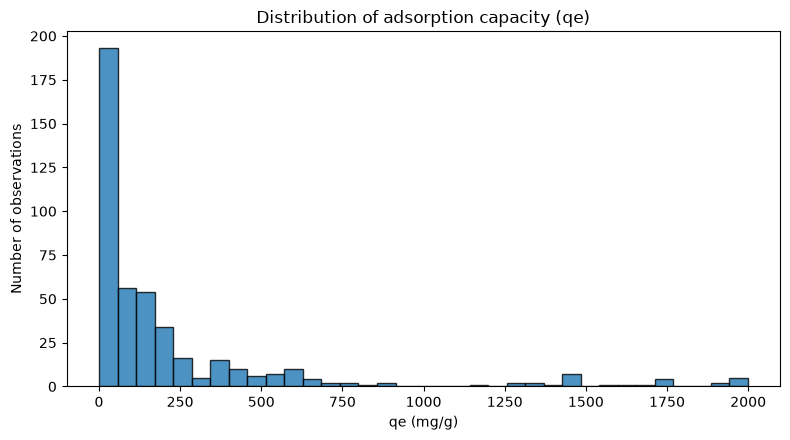

Target quantiles (mg/g):


,qe_mgg
0.00,0.25000
0.05,3.85550
0.25,19.87375
0.50,92.65000
0.75,220.25000
0.90,574.08000
0.95,1324.91000
0.99,1932.76300
1.00,1998.10000


Training rows: 355 | Hold-out test rows: 89


In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(model_df[TARGET].dropna(), bins=35, edgecolor="black", alpha=0.8)
ax.set_title("Distribution of adsorption capacity (qe)")
ax.set_xlabel("qe (mg/g)")
ax.set_ylabel("Number of observations")
plt.tight_layout()
plt.show()

print("Target quantiles (mg/g):")
display(model_df[TARGET].quantile([0, .05, .25, .5, .75, .9, .95, .99, 1]).rename("qe_mgg").to_frame())

X = model_df[FEATURES].copy()
y = model_df[TARGET].astype(float).copy()
source_rows = model_df["_excel_row"].copy()

X_train, X_test, y_train, y_test, rows_train, rows_test = train_test_split(
    X, y, source_rows,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    shuffle=True,
)
print(f"Training rows: {len(X_train)} | Hold-out test rows: {len(X_test)}")

## 5. Fit and evaluate the first Linear Regression baseline

Preprocessing is part of a scikit-learn `Pipeline`: median imputation and standardization are fitted on training data only. A simple training-set median predictor is included as a reference, because a useful model should improve on predicting one constant value for every observation.

Metrics:
- **MAE:** average absolute prediction error in mg/g (lower is better).
- **RMSE:** more strongly penalizes large errors, in mg/g (lower is better).
- **R²:** explained variance relative to a mean predictor; it can be negative on unseen test data.

In [9]:
model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression()),
])

# Cross-validation is carried out on the training partition only.
cv = KFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)
cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2",
    },
    return_train_score=False,
    n_jobs=None,
)
cv_summary = pd.DataFrame({
    "metric": ["MAE (mg/g)", "RMSE (mg/g)", "R²"],
    "mean_across_folds": [
        -cv_results["test_MAE"].mean(),
        -cv_results["test_RMSE"].mean(),
        cv_results["test_R2"].mean(),
    ],
    "standard_deviation": [
        cv_results["test_MAE"].std(ddof=1),
        cv_results["test_RMSE"].std(ddof=1),
        cv_results["test_R2"].std(ddof=1),
    ],
})
print("Training-set 5-fold CV (row-wise; not source-grouped):")
display(cv_summary.round(4))

# Fit once on training data, evaluate once on the untouched hold-out set.
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
median_prediction = np.full(shape=len(y_test), fill_value=float(y_train.median()))

def calculate_metrics(y_true, y_hat):
    return {
        "MAE (mg/g)": mean_absolute_error(y_true, y_hat),
        "RMSE (mg/g)": float(np.sqrt(mean_squared_error(y_true, y_hat))),
        "R²": r2_score(y_true, y_hat),
    }

holdout_metrics = pd.DataFrame([
    {"model": "Training median baseline", **calculate_metrics(y_test, median_prediction)},
    {"model": "Linear Regression", **calculate_metrics(y_test, y_pred)},
])
print("Hold-out test performance:")
display(holdout_metrics.round(4))

Training-set 5-fold CV (row-wise; not source-grouped):


,metric,mean_across_folds,standard_deviation
0,MAE (mg/g),176.9265,14.8946
1,RMSE (mg/g),242.4323,29.0979
2,R²,0.5417,0.1297


Hold-out test performance:


,model,MAE (mg/g),RMSE (mg/g),R²
0,Training median baseline,204.5960,445.2840,-0.0906
1,Linear Regression,166.2377,226.4266,0.7180


,excel_row,qe_actual_mgg,qe_predicted_mgg,residual_mgg,absolute_error_mgg
0,2,43.20,31.863506,11.336494,11.336494
1,11,98.50,102.610346,-4.110346,4.110346
2,13,131.80,150.565218,-18.765218,18.765218
3,17,45.30,152.727478,-107.427478,107.427478
4,21,162.50,241.401926,-78.901926,78.901926
5,24,40.70,345.710791,-305.010791,305.010791
6,26,101.90,371.454985,-269.554985,269.554985
7,27,213.50,418.400281,-204.900281,204.900281
8,32,30.57,-15.620731,46.190731,46.190731
9,35,144.92,46.145556,98.774444,98.774444


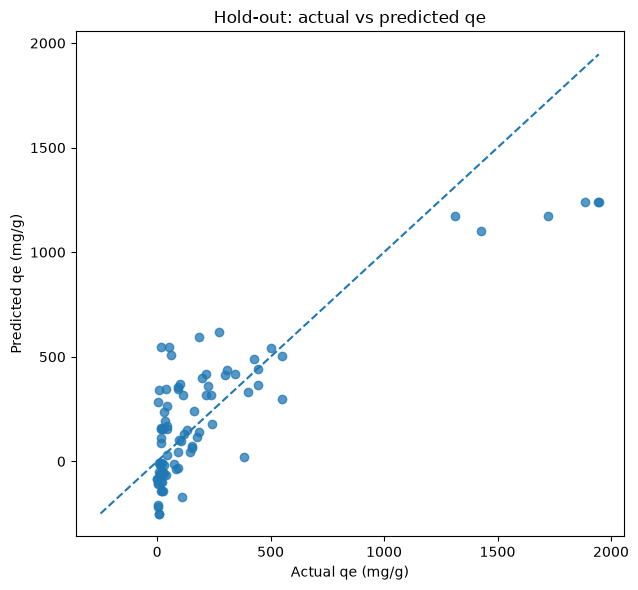

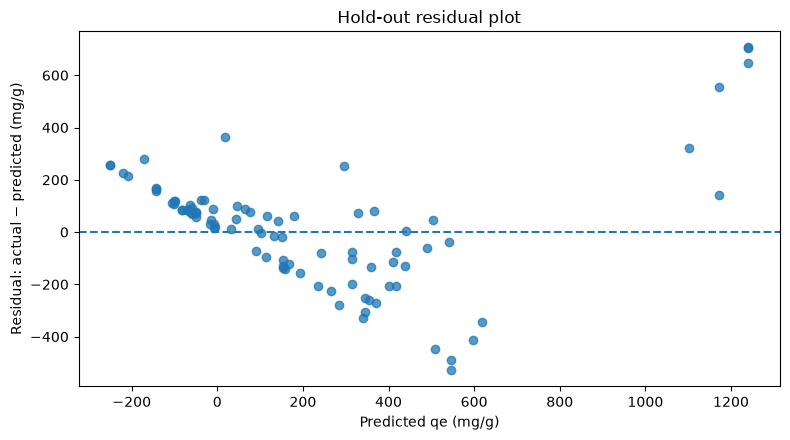

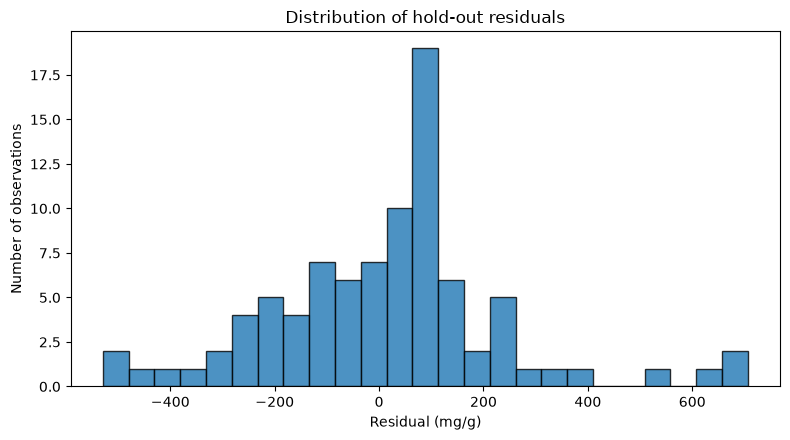

In [10]:
# Show what the model predicts for the test rows, linked back to original Excel row numbers.
predictions = pd.DataFrame({
    "excel_row": rows_test.to_numpy(),
    "qe_actual_mgg": y_test.to_numpy(),
    "qe_predicted_mgg": y_pred,
})
predictions["residual_mgg"] = predictions["qe_actual_mgg"] - predictions["qe_predicted_mgg"]
predictions["absolute_error_mgg"] = predictions["residual_mgg"].abs()
predictions = predictions.sort_values("excel_row").reset_index(drop=True)
display(predictions.head(20))

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(y_test, y_pred, alpha=0.75)
low = float(min(y_test.min(), np.min(y_pred)))
high = float(max(y_test.max(), np.max(y_pred)))
ax.plot([low, high], [low, high], linestyle="--")
ax.set_title("Hold-out: actual vs predicted qe")
ax.set_xlabel("Actual qe (mg/g)")
ax.set_ylabel("Predicted qe (mg/g)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(y_pred, y_test.to_numpy() - y_pred, alpha=0.75)
ax.axhline(0, linestyle="--")
ax.set_title("Hold-out residual plot")
ax.set_xlabel("Predicted qe (mg/g)")
ax.set_ylabel("Residual: actual − predicted (mg/g)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(predictions["residual_mgg"], bins=25, edgecolor="black", alpha=0.8)
ax.set_title("Distribution of hold-out residuals")
ax.set_xlabel("Residual (mg/g)")
ax.set_ylabel("Number of observations")
plt.tight_layout()
plt.show()

## 6. Interpret the fitted coefficients carefully

The input features were standardized in the pipeline, so these coefficients describe the linear model's change in predicted `qe_mgg` per one standard deviation of a transformed input feature. Missingness-indicator coefficients are included when a feature had missing values in the training data. Coefficients are not causal effects, and correlated features can make them unstable.

,transformed_feature,standardized_coefficient_mgg_per_sd,absolute_coefficient
0,BET_m2g,145.1513,145.1513
1,dose_gL,-124.1525,124.1525
2,missingindicator_C0_mgL,107.5522,107.5522
3,C0_mgL,69.8797,69.8797
4,missingindicator_pH_pzc,-55.2758,55.2758
5,pore_vol_cm3g,52.3476,52.3476
6,missingindicator_contact_time_min,-47.1601,47.1601
7,temp_K,46.5267,46.5267
8,pH_pzc,-46.1044,46.1044
9,missingindicator_temp_K,-45.5535,45.5535


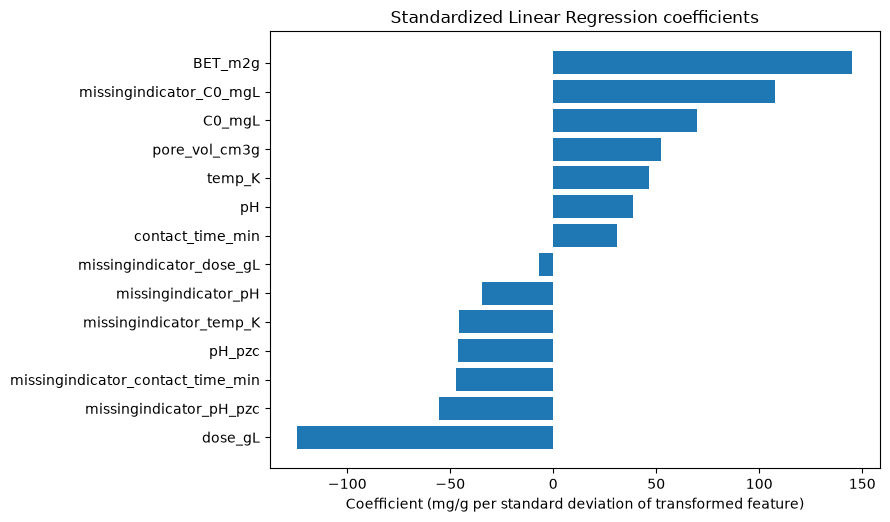

In [11]:
imputer = model.named_steps["imputer"]
feature_names_after_imputation = imputer.get_feature_names_out(FEATURES)
coefficients = model.named_steps["regressor"].coef_
coefficient_table = pd.DataFrame({
    "transformed_feature": feature_names_after_imputation,
    "standardized_coefficient_mgg_per_sd": coefficients,
})
coefficient_table["absolute_coefficient"] = coefficient_table["standardized_coefficient_mgg_per_sd"].abs()
coefficient_table = coefficient_table.sort_values("absolute_coefficient", ascending=False).reset_index(drop=True)
display(coefficient_table.round(4))

fig, ax = plt.subplots(figsize=(9, max(4, 0.38 * len(coefficient_table))))
plot_coef = coefficient_table.sort_values("standardized_coefficient_mgg_per_sd")
ax.barh(plot_coef["transformed_feature"], plot_coef["standardized_coefficient_mgg_per_sd"])
ax.set_title("Standardized Linear Regression coefficients")
ax.set_xlabel("Coefficient (mg/g per standard deviation of transformed feature)")
plt.tight_layout()
plt.show()

## 7. Predict adsorption capacity for a new experiment

Supply values using the same units as the workbook. `Ce_mgL` is intentionally not accepted as a feature. Any omitted/`None` predictor will be imputed to the training-set median, so the function prints a warning when inputs are incomplete. For a meaningful prediction, enter all available measurements and avoid extrapolating far outside the training data.

In [12]:
def predict_qe(input_values: dict) -> float:
    """Predict qe (mg/g) from an input dict keyed by the eight FEATURES above.

    Missing feature values are imputed by the fitted training pipeline; use complete,
    unit-consistent values wherever possible. Do not pass Ce_mgL.
    """
    if not isinstance(input_values, dict):
        raise TypeError("input_values must be a dictionary, e.g. {'BET_m2g': 500, ...}")
    unexpected = sorted(set(input_values) - set(FEATURES))
    if unexpected:
        raise ValueError(f"Unexpected feature(s): {unexpected}. Allowed features: {FEATURES}")
    new_x = pd.DataFrame([{feature: input_values.get(feature, np.nan) for feature in FEATURES}])
    new_x = new_x.apply(pd.to_numeric, errors="coerce")
    absent_or_missing = [c for c in FEATURES if pd.isna(new_x.loc[0, c])]
    if absent_or_missing:
        print("Warning: these predictor(s) are missing and will be median-imputed:", absent_or_missing)
    return float(model.predict(new_x)[0])

# Example template (intentionally not executed, so no made-up example prediction is presented):
# new_experiment = {
#     "BET_m2g": 500,
#     "pore_vol_cm3g": 0.4,
#     "pH_pzc": 7.0,
#     "C0_mgL": 100,
#     "pH": 6.0,
#     "dose_gL": 1.0,
#     "contact_time_min": 120,
#     "temp_K": 298.15,
# }
# predict_qe(new_experiment)

## 8. Save the audit trail, test predictions and fitted model

Files are saved beside the Excel workbook. Keep the original workbook as the source of truth. The cleaned CSV is an audit/export copy and includes the original Excel row number, original pH text, and a flag for pH intervals converted to midpoints.

In [13]:
# Export an audit-friendly numeric copy. This does not overwrite the Excel workbook.
cleaned_export_path = OUTPUT_DIR / "adsorption_cleaned_for_baseline.csv"
prediction_path = OUTPUT_DIR / "adsorption_linear_regression_test_predictions.csv"
metrics_path = OUTPUT_DIR / "adsorption_linear_regression_metrics.json"
coefficient_path = OUTPUT_DIR / "adsorption_linear_regression_coefficients.csv"
mass_balance_path = OUTPUT_DIR / "adsorption_mass_balance_audit.csv"
model_path = OUTPUT_DIR / "adsorption_linear_regression_model.joblib"

model_df.to_csv(cleaned_export_path, index=False)
predictions.to_csv(prediction_path, index=False)
coefficient_table.to_csv(coefficient_path, index=False)
mb.to_csv(mass_balance_path, index=False)

metrics_payload = {
    "input_workbook": DATA_PATH.name,
    "target_column": TARGET,
    "target_units": "mg/g",
    "features": FEATURES,
    "excluded_leakage_risk_columns": LEAKAGE_RISK_COLUMNS,
    "excluded_high_missingness_columns": COMPOSITION_COLUMNS,
    "rows_in_source_workbook": int(len(raw_df)),
    "exact_duplicate_extra_copies_detected": int(duplicate_mask_raw.sum()),
    "exact_duplicates_removed_from_model": int(duplicate_mask_raw.sum()) if REMOVE_EXACT_DUPLICATES else 0,
    "rows_used_for_model": int(len(model_df)),
    "rows_train": int(len(X_train)),
    "rows_test": int(len(X_test)),
    "pH_interval_rows_midpoint_approximated": int(ph_range_mask.sum()) if CONVERT_PH_RANGES_TO_MIDPOINT else 0,
    "mass_balance_rows_checked": int(len(mb)),
    "mass_balance_rows_with_abs_difference_over_2_mg_g": int((mb["absolute_difference_mgg"] > 2).sum()) if len(mb) else 0,
    "maximum_mass_balance_absolute_difference_mg_g": float(mb["absolute_difference_mgg"].max()) if len(mb) else None,
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "validation_note": "Row-wise random split only; source/material identifiers are absent, so test performance is preliminary and may be optimistic.",
    "cross_validation_train_only": {
        "MAE_mean_mg_g": float(-cv_results["test_MAE"].mean()),
        "MAE_sd_mg_g": float(cv_results["test_MAE"].std(ddof=1)),
        "RMSE_mean_mg_g": float(-cv_results["test_RMSE"].mean()),
        "RMSE_sd_mg_g": float(cv_results["test_RMSE"].std(ddof=1)),
        "R2_mean": float(cv_results["test_R2"].mean()),
        "R2_sd": float(cv_results["test_R2"].std(ddof=1)),
    },
    "holdout_test_metrics": {
        "median_baseline": calculate_metrics(y_test, median_prediction),
        "linear_regression": calculate_metrics(y_test, y_pred),
    },
}
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics_payload, f, indent=2)

joblib.dump({
    "model": model,
    "features": FEATURES,
    "target_column": TARGET,
    "target_units": "mg/g",
    "random_state": RANDOM_STATE,
    "data_file": DATA_PATH.name,
    "limitations": [
        "No pollutant, material, or paper/DOI identifiers in the provided workbook.",
        "Evaluation uses a row-wise random split and is only a preliminary benchmark.",
        "Ce_mgL excluded because it is measured after adsorption and is algebraically related to qe.",
        "pH intervals, if present, are converted to midpoints and flagged in the audit copy.",
    ],
}, model_path)

print("Saved files:")
for path in [cleaned_export_path, prediction_path, metrics_path, coefficient_path, mass_balance_path, model_path]:
    print(f" - {path}")
print("\nFinal reminder: do not report the random-split score as performance on unseen materials until source/material IDs and grouped validation are available.")

Saved files:
 - D:\Downloads\Project\adsorption_cleaned_for_baseline.csv
 - D:\Downloads\Project\adsorption_linear_regression_test_predictions.csv
 - D:\Downloads\Project\adsorption_linear_regression_metrics.json
 - D:\Downloads\Project\adsorption_linear_regression_coefficients.csv
 - D:\Downloads\Project\adsorption_mass_balance_audit.csv
 - D:\Downloads\Project\adsorption_linear_regression_model.joblib

Final reminder: do not report the random-split score as performance on unseen materials until source/material IDs and grouped validation are available.
